In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:

from google.colab import drive
import os

drive.mount('/content/drive')

project_path = '/content/drive/MyDrive/Cat_vs_Dog_Image_Classification'
os.makedirs(project_path, exist_ok=True)

print("Project folder created successfully!")
print(project_path)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project folder created successfully!
/content/drive/MyDrive/Cat_vs_Dog_Image_Classification


In [ ]:


import os
import shutil

project_path = '/content/drive/MyDrive/Cat_vs_Dog_Image_Classification'
source_path = '/content/cats_and_dogs_filtered/train'

for animal in ['cats', 'dogs']:
    source_folder = os.path.join(source_path, animal)
    destination_folder = os.path.join(
        project_path, animal.capitalize()
    )

    os.makedirs(destination_folder, exist_ok=True)

    if not os.path.isdir(source_folder):
        print("Source folder not found:", source_folder)
        continue

    files = [
        f for f in os.listdir(source_folder)
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ]

    print(animal, "available images:", len(files))

    for filename in files[:50]:
        shutil.copy2(
            os.path.join(source_folder, filename),
            os.path.join(destination_folder, filename)
        )

    saved_files = [
        f for f in os.listdir(destination_folder)
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ]

    print(animal, "images in Drive:", len(saved_files))



Source folder not found: /content/cats_and_dogs_filtered/train/cats
Source folder not found: /content/cats_and_dogs_filtered/train/dogs


In [ ]:

import os
import urllib.request
import zipfile
import shutil

project = "/content/drive/MyDrive/Cat_vs_Dog_Image_Classification"
zip_file = "/content/cat_dog_images.zip"
url = "https://storage.googleapis.com/mledu-datasets/cats_and_dogs_filtered.zip"

os.makedirs(project + "/Cats", exist_ok=True)
os.makedirs(project + "/Dogs", exist_ok=True)

try:
    print("Downloading dataset...")

    request = urllib.request.Request(
        url, headers={"User-Agent": "Mozilla/5.0"}
    )

    with urllib.request.urlopen(request, timeout=120) as response:
        with open(zip_file, "wb") as f:
            shutil.copyfileobj(response, f)

    print("Download complete!")

    with zipfile.ZipFile(zip_file, "r") as z:
        z.extractall("/content/cat_dog_data")

    root = "/content/cat_dog_data/cats_and_dogs_filtered/train"

    for animal in ["cats", "dogs"]:
        src = os.path.join(root, animal)
        dst = os.path.join(project, animal.capitalize())

        images = [
            f for f in os.listdir(src)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ]

        for filename in images[:50]:
            shutil.copy2(
                os.path.join(src, filename),
                os.path.join(dst, filename)
            )

        print(animal.capitalize(), "saved:", len(images[:50]))

    print("Finished. Check your Google Drive folders.")

except Exception as e:
    print("Download failed:", repr(e))
    print("Send me this exact error message.")


Download failed: <HTTPError 403: 'Forbidden'>
Send me this exact error message.


In [ ]:

from google.colab import files

uploaded = files.upload()

Saving cats_dogs_light.zip to cats_dogs_light.zip


In [ ]:

import os

zip_path = "/content/cats_dogs_light.zip"

if os.path.exists(zip_path):
    print("ZIP file is available in Colab.")
else:
    print("ZIP file needs to be uploaded again.")


ZIP file is available in Colab.


In [ ]:

import zipfile
import os

zip_path = "/content/cats_dogs_light.zip"
extract_path = "/content/cats_dogs_extracted"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction completed successfully!")

for root, dirs, files in os.walk(extract_path):
    print("\nFolder:", root)
    print("Subfolders:", dirs[:5])
    print("Sample files:", files[:5])


Extraction completed successfully!

Folder: /content/cats_dogs_extracted
Subfolders: ['cats_dogs_light']
Sample files: []

Folder: /content/cats_dogs_extracted/cats_dogs_light
Subfolders: ['train', 'test']
Sample files: []

Folder: /content/cats_dogs_extracted/cats_dogs_light/train
Subfolders: []
Sample files: ['dog.10106.jpg', 'dog.10051.jpg', 'cat.1003.jpg', 'cat.10111.jpg', 'cat.10012.jpg']

Folder: /content/cats_dogs_extracted/cats_dogs_light/test
Subfolders: []
Sample files: ['cat.9998.jpg', 'dog.9848.jpg', 'cat.9988.jpg', 'cat.9989.jpg', 'cat.9833.jpg']


In [ ]:

import os
import shutil

source_folder = "/content/cats_dogs_extracted/cats_dogs_light/train"

project_folder = "/content/drive/MyDrive/Cat_vs_Dog_Image_Classification"
cats_folder = os.path.join(project_folder, "Cats")
dogs_folder = os.path.join(project_folder, "Dogs")

os.makedirs(cats_folder, exist_ok=True)
os.makedirs(dogs_folder, exist_ok=True)

# Select 50 cat images and 50 dog images
files = sorted(os.listdir(source_folder))

cat_images = [f for f in files if f.startswith("cat.")][:50]
dog_images = [f for f in files if f.startswith("dog.")][:50]

for filename in cat_images:
    shutil.copy2(
        os.path.join(source_folder, filename),
        os.path.join(cats_folder, filename)
    )

for filename in dog_images:
    shutil.copy2(
        os.path.join(source_folder, filename),
        os.path.join(dogs_folder, filename)
    )

print("Cat images saved:", len(cat_images))
print("Dog images saved:", len(dog_images))
print("Total images saved:", len(cat_images) + len(dog_images))
print("Google Drive location:", project_folder)


Cat images saved: 50
Dog images saved: 50
Total images saved: 100
Google Drive location: /content/drive/MyDrive/Cat_vs_Dog_Image_Classification


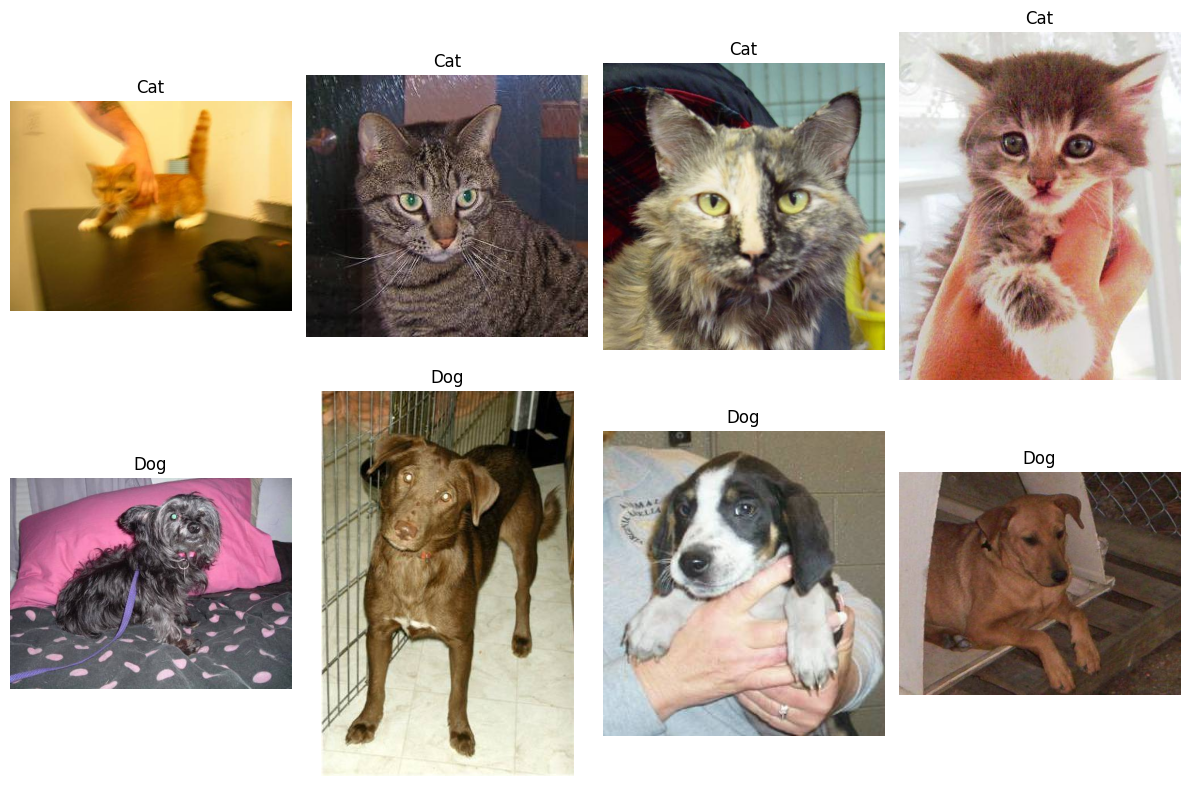

In [ ]:

from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import os

dataset_path = "/content/cats_dogs_extracted/cats_dogs_light/train"

files = sorted(os.listdir(dataset_path))

cat_images = [f for f in files if f.startswith("cat.")][:4]
dog_images = [f for f in files if f.startswith("dog.")][:4]

selected_images = cat_images + dog_images

plt.figure(figsize=(12, 8))

for i, filename in enumerate(selected_images):
    image_path = os.path.join(dataset_path, filename)

    image = Image.open(image_path).convert("RGB")
    image_array = np.array(image)

    plt.subplot(2, 4, i + 1)
    plt.imshow(image_array)
    plt.title("Cat" if filename.startswith("cat.") else "Dog")
    plt.axis("off")

plt.tight_layout()
plt.show()


In [ ]:
import os

project_folder = "/content/drive/MyDrive/Cat_vs_Dog_Image_Classification"

cats_folder = os.path.join(project_folder, "Cats")
dogs_folder = os.path.join(project_folder, "Dogs")

cat_images = os.listdir(cats_folder)
dog_images = os.listdir(dogs_folder)

print("Total Cat Images:", len(cat_images))
print("Total Dog Images:", len(dog_images))
print("Total Images:", len(cat_images) + len(dog_images))

Total Cat Images: 50
Total Dog Images: 50
Total Images: 100
